# Learning Where to Return a Serve: a One-Shot RL Env

- This notebook turns the Milestone 2 model into a Gymnasium env, where player 2
  learns where to aim the return of a serve from a reward of 1 for a winner, in
  tennis and pickleball (#713)
- The pedagogical arc:
  - The env: one point, one shot, a contextual bandit
  - Brute force: the winner probability of every target, through the env
  - Milestone 2 recomputed on the same grid, and compared with the brute force
  - PPO learns the target from the reward only
  - The targets of PPO against both maps, with a strict pass rule

In [1]:
# Install the CPU-only `torch` first: about 200 MB and 1 to 3 minutes the first
# time. From PyPI, `stable-baselines3` would pull the CUDA build, about 1.9 GB.
!pip install -q torch==2.14.1 --index-url https://download.pytorch.org/whl/cpu
!pip install -q gymnasium==1.3.0 stable-baselines3==2.9.2

import gymnasium
import stable_baselines3
import torch

print("torch version: ", torch.__version__)
print("gymnasium version: ", gymnasium.__version__)
print("stable-baselines3 version: ", stable_baselines3.__version__)

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


torch version:  2.14.1+cpu
gymnasium version:  1.3.0
stable-baselines3 version:  2.9.2


In [2]:
%load_ext autoreload
%autoreload 2

import functools
import inspect
import logging

import gymnasium as gym
import numpy as np
import pandas as pd
import stable_baselines3 as sb3
from gymnasium.utils.env_checker import check_env

In [3]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook

from research.Optimal_strategy_for_racket_sports import racket_params
from research.Optimal_strategy_for_racket_sports.notebooks import (
    racket_sports_06_rl_return_utils as utils,
)

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpyorm03oo.json --HistoryManager.hist_file=:memory:


# Part 0: How Much to Run

## Cell 0.1: Reduced or Full Run

- The reduced run takes about 10 minutes on a CPU
  - The middle serve of the deuce box, 1000 points per target, and one PPO run of
    50k steps with seed 0
- The full run takes about 1 hour and gives the results of #713
  - 9 serves on a 3 x 3 grid over the deuce box, 1000 points per target, and 3
    PPO runs of 75k steps with the fresh seeds 3, 4, and 5
- Both use the Milestone 2 defaults, its grid, and a fresh Milestone 2 map with
  5000 samples per target and seed 2 (Milestone 2 used seed 1)
- The saved outputs of this notebook are from the full run

In [4]:
# Set to `True` for the full run.
RUN_FULL_SIMS = False
config = utils.get_experiment_config(RUN_FULL_SIMS)
print("RUN_FULL_SIMS=", RUN_FULL_SIMS)
print("config=", config)
sports = [racket_params.TENNIS, racket_params.PICKLEBALL]

RUN_FULL_SIMS= True
config= ExperimentConfig(n_serves_per_side=3, n_samples=1000, env_seed=1000, m2_n_samples=5000, m2_seed=2, total_timesteps=75000, seeds=(3, 4, 5))


# Part 1: The Env

## Cell 1.1: Read the Code of the Env

**Goal**
- See the 4 pieces of the env: the 2 spaces, `reset()`, and `step()`
- See that `step()` is one call of the Milestone 2 function
  `compute_winner_probability()` with 1 sample, so the env has no model of its own

In [5]:
# Print the code of the env, which lives in the utils.
print(inspect.getsource(utils.ReturnEnv))

class ReturnEnv(gym.Env):
    """
    One point with one shot: player 2 aims the return of a serve, and gets a
    reward of 1 for a winner, else 0.

    - Observation: 6 floats in meters, player 1 `(x, y)`, player 2 `(x, y)`,
      and the serve landing `(x1, y1)`
      - In v0 player 1 stays at `get_player1_xy()` and player 2 hits from the
        serve landing, as in Milestone 2, so only the serve varies
    - Action: a cell of `racket_scoring.make_target_grid()` over player 1's
      half; the return aims at its center
    - Transition: `compute_winner_probability()` with 1 sample, so a winner
      is the Milestone 2 event, in and not reached
    - Episode: 1 step, which ends as terminated; the serve is the context, so
      the env is a contextual bandit
    """

    def __init__(
        self,
        sport: racket_params.SportParams,
        grid_step_m: float,
        ball_speed_mps: float,
        *,
        std_xy: Tuple[float, float] = _STD_DEFAULT_M,
        reaction_time_

**Guided usage**
- Find the line that sets the reward in `step()`
  - Observe that the reward is the `p_winner` of a 1-sample call: 1 for a winner,
    in and not reached, else 0
- Find where `reset()` draws the serve
  - Observe that every draw comes from `self.np_random`, so a seed fixes the point

## Cell 1.2: Create the Env for Both Sports

**Goal**
- Build one env per sport with the Milestone 2 defaults, and read the task from
  the spaces

In [6]:
# Build one env per sport, with the Milestone 2 grid and ball speed.
envs = {sport.name: utils.build_env(sport) for sport in sports}
for name, env in envs.items():
    print(f"{name}: observation_space=", env.observation_space)
    print(
        f"{name}: action_space=", env.action_space, "grid_size=", env.grid_size
    )
    print(f"{name}: serve_box=", env.serve_box)
# Outcome: `Discrete(150)` and `Discrete(90)`, the grids of Milestone 2.

Tennis: observation_space= Box([ -4.115 -11.885  -4.115 -11.885  -4.115 -11.885], [ 4.115 11.885  4.115 11.885  4.115 11.885], (6,), float32)
Tennis: action_space= Discrete(150) grid_size= (10, 15)
Tennis: serve_box= CourtRegion(x_min=-4.115, x_max=0, y_min=0.0, y_max=6.4)
Pickleball: observation_space= Box([-3.05  -6.705 -3.05  -6.705 -3.05  -6.705], [3.05  6.705 3.05  6.705 3.05  6.705], (6,), float32)
Pickleball: action_space= Discrete(90) grid_size= (9, 10)
Pickleball: serve_box= CourtRegion(x_min=-3.05, x_max=0, y_min=2.13, y_max=6.705)


**Guided usage**
- Read the action spaces
  - Observe 150 targets in tennis and 90 in pickleball: the grids of Milestone 2
- Read the bounds of the observation space
  - Observe 3 points, player 1, player 2, and the serve, each bounded by the court

## Cell 1.3: Play One Point

**Goal**
- Reset with a fixed serve and aim at 2 targets: the middle of player 1's half,
  and the cell in front of player 1
- See the outcome in `info`, and that one shot ends the point

In [7]:
# Aim 2 returns from the middle serve of the tennis deuce box, with the same seed.
env = envs["Tennis"]
serve_xy = utils.get_eval_serves(env, 1, 1)[0]
middle_xy = (0.0, -env.sport.court.length_m / 4)
targets = {
    "middle": utils.get_nearest_action(env, middle_xy),
    "near player 1": utils.get_nearest_action(env, env.player1_xy),
}
seed = 0
obs, _ = env.reset(seed=seed, options={"serve_xy": serve_xy})
print("obs=", obs)
for label, action in targets.items():
    env.reset(seed=seed, options={"serve_xy": serve_xy})
    _, reward, terminated, truncated, info = env.step(action)
    print(f"{label}: action={action} reward={reward} info={info}")
    print(f"  terminated={terminated} truncated={truncated}")
# Outcome: with seed 0, a winner in the middle, and a return in front of player 1
# that they reach.

obs= [  0.     -11.885   -2.0575   3.2     -2.0575   3.2   ]
middle: action=74 reward=1.0 info={'is_in': True, 'is_reached': False, 'target_xy': (-0.4115, -5.9425)}
  terminated=True truncated=False
near player 1: action=4 reward=0.0 info={'is_in': True, 'is_reached': True, 'target_xy': (-0.4115, -11.488833333333332)}
  terminated=True truncated=False


**Guided usage**
- Change `seed`
  - Observe the middle target stay a winner for every seed, while the target in
    front of player 1 wins about half the time: about a third of its returns
    land out past the baseline, and a fifth are reached
- Read `terminated` and `truncated`
  - Observe that one shot ends the point as terminated, not truncated

## Cell 1.4: Check the Env Against the Gymnasium API

**Goal**
- Run the checks that Gymnasium ships for custom envs, before any training: the
  spaces, the types that `reset()` and `step()` return, and the seeding

In [8]:
# Check each env; the env has no render modes, so skip the render check.
for name, env in envs.items():
    check_env(env, skip_render_check=True)
    print(f"{name}: check_env passed")
# Outcome: both envs pass.

Tennis: check_env passed
Pickleball: check_env passed


**Guided usage**
- Replace `self.np_random` with `np.random.default_rng()` in `step()` in a copy
  of the env
  - Observe that `check_env()` may still pass, since it compares one step, while
    the unit test that compares 50 seeded points fails

# Part 2: Brute Force Through the Env

## Cell 2.1: Score Every Target of Each Serve

**Goal**
- Estimate the winner probability of every target with the env only: points
  played through `reset()` and `step()`, with the same reset seeds for every
  target (common random numbers)

**Description**
- Inputs
  - `config.n_serves_per_side`: 1 gives the middle serve, 3 gives 9 serves
  - `config.n_samples`: points per target

- Panels
  - `Top targets`: the 3 targets with the highest winner probability of the
    middle serve, per sport

In [9]:
# Score every target of every serve through the env, for each sport.
serves = {}
env_maps = {}
for name, env in envs.items():
    n = config.n_serves_per_side
    serves[name] = utils.get_eval_serves(env, n, n)
    env_maps[name] = [
        utils.compute_env_heatmap(env, serve, config.n_samples, config.env_seed)
        for serve in serves[name]
    ]
# The middle serve: the only one of the reduced run, the 5th of 9 in the full run.
middle = config.n_serves_per_side**2 // 2
columns = ["cell_id", "x_m", "y_m", "p_winner", "p_winner_se"]
for name in envs:
    print(f"{name}: middle serve {serves[name][middle]}")
    display(env_maps[name][middle].nlargest(3, "p_winner")[columns])

Tennis: middle serve (-2.0575, 3.2)


,cell_id,x_m,y_m,p_winner,p_winner_se
42,42,-2.0575,-8.3195,1.0,0.0
43,43,-1.2345,-8.3195,1.0,0.0
44,44,-0.4115,-8.3195,1.0,0.0


Pickleball: middle serve (-1.525, 4.4175)


,cell_id,x_m,y_m,p_winner,p_winner_se
47,47,-1.355556,-3.01725,0.998,0.001413
48,48,-0.677778,-3.01725,0.998,0.001413
42,42,1.355556,-3.68775,0.996,0.001996


**Guided usage**
- Read the top targets of tennis
  - Observe several targets at the same winner probability: a plateau
- Set `RUN_FULL_SIMS = True` in Cell 0.1 and rerun
  - Observe 9 serves per sport instead of the middle one, in about 1 hour

**Implementation** `utils.compute_env_heatmap(env, serve_xy, n_samples, seed)`
- Plays `n_samples` points per target, each a `reset()` with the serve and the
  seed `seed + k` and a `step()` aimed at the target
- Averages the rewards per target into `p_winner`, with the standard error of a
  fraction, in the columns of `compute_winner_heatmap()`

In [10]:
hintros.print_obj_info(utils.compute_env_heatmap)

- `compute_env_heatmap(env: research.Optimal_strategy_for_racket_sports.notebooks.racket_sports_06_rl_return_utils.ReturnEnv, serve_xy: Tuple[float, float], n_samples: int, seed: int) -> pandas.DataFrame`  
  Estimate the probability of a winner of every target by playing the env.

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/research/Optimal_strategy_for_racket_sports/notebooks/racket_sports_06_rl_return_utils.py#L354


## Cell 2.2: Map of the Brute Force and Its Best Region

**Goal**
- See where the winners are: the brute force map of the middle serve on the court

**Description**
- Panels
  - `Brute force`: one panel per sport, each cell colored by its winner
    probability from red (0) to green (1), the best region outlined (the cells
    within 2 standard errors of the highest), its middle as a star, and the 2
    players as dots

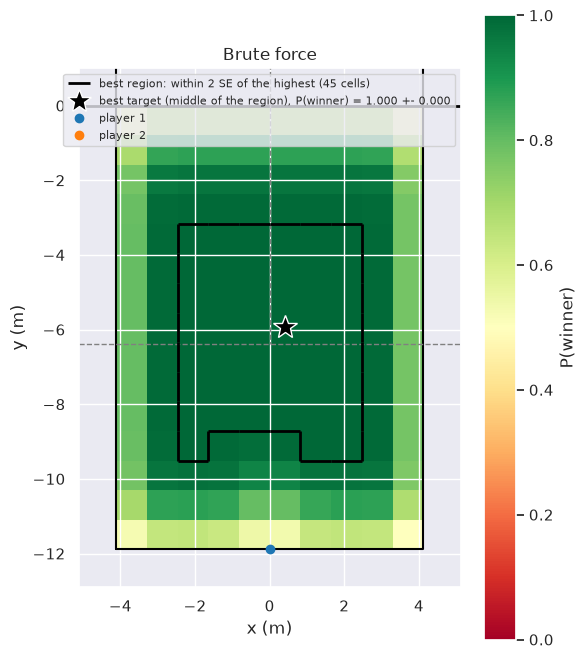

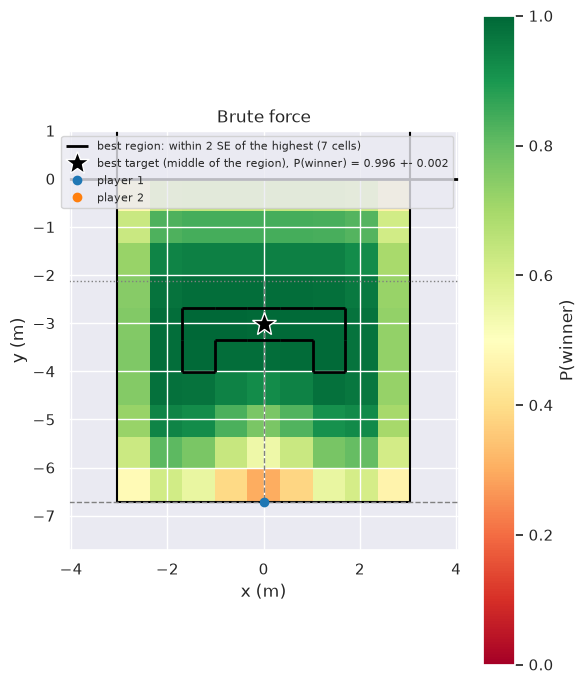

In [11]:
# Plot the brute force map of the middle serve, for each sport.
for sport in sports:
    name = sport.name
    _ = utils.plot_heatmaps(
        {"Brute force": env_maps[name][middle]},
        sport.court,
        serves[name][middle],
        figsize=(6.0, 7.0),
    )

**Guided usage**
- Compare the 2 sports
  - Observe a large best region in tennis and a small one in pickleball

**Implementation** `utils.plot_heatmaps(heatmaps, court, serve_xy, targets_xy=(),
figsize=None)`
- Draws one panel per map with `plot_winner_heatmap()` of notebook 01
- Marks `targets_xy` on every panel, and crops each panel to player 1's half

In [12]:
hintros.print_obj_info(utils.plot_heatmaps)

- `plot_heatmaps(heatmaps: Dict[str, pandas.DataFrame], court: research.Optimal_strategy_for_racket_sports.racket_params.CourtGeometry, serve_xy: Tuple[float, float], *, targets_xy: Tuple[Tuple[float, float], ...] = (), figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot maps of one serve side by side, with the targets of a policy.

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/research/Optimal_strategy_for_racket_sports/notebooks/racket_sports_06_rl_return_utils.py#L631


# Part 3: Milestone 2 Recomputed

## Cell 3.1: Recompute the Milestone 2 Map on the Same Grid

**Goal**
- Compute the Milestone 2 map now, with the settings and the grid of the env and
  a new seed, instead of reading a saved result

In [13]:
# Recompute the Milestone 2 map of every serve, for each sport.
m2_maps = {
    name: [
        utils.compute_m2_heatmap(
            envs[name], serve, config.m2_n_samples, config.m2_seed
        )
        for serve in serves[name]
    ]
    for name in envs
}
for name in envs:
    print(f"{name}: middle serve {serves[name][middle]}")
    display(m2_maps[name][middle].nlargest(3, "p_winner")[columns])

Tennis: middle serve (-2.0575, 3.2)


,cell_id,x_m,y_m,p_winner,p_winner_se
52,52,-2.0575,-7.527167,1.0,0.0
53,53,-1.2345,-7.527167,1.0,0.0
54,54,-0.4115,-7.527167,1.0,0.0


Pickleball: middle serve (-1.525, 4.4175)


,cell_id,x_m,y_m,p_winner,p_winner_se
47,47,-1.355556,-3.01725,0.9982,0.000599
51,51,1.355556,-3.01725,0.9978,0.000663
48,48,-0.677778,-3.01725,0.9970,0.000773


**Guided usage**
- Compare with Cell 2.1
  - Observe top targets with a winner probability at or close to 1 in both maps,
    on different cells: both maps have a plateau of near ties

**Implementation** `utils.compute_m2_heatmap(env, serve_xy, n_samples, seed)`
- Calls `compute_winner_heatmap()` of notebook 01 with the spread, the speeds,
  the court, and the grid of the env

In [14]:
hintros.print_obj_info(utils.compute_m2_heatmap)

- `compute_m2_heatmap(env: research.Optimal_strategy_for_racket_sports.notebooks.racket_sports_06_rl_return_utils.ReturnEnv, serve_xy: Tuple[float, float], n_samples: int, seed: int) -> pandas.DataFrame`  
  Compute the Milestone 2 heatmap with the settings and the grid of the env.

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/research/Optimal_strategy_for_racket_sports/notebooks/racket_sports_06_rl_return_utils.py#L398


## Cell 3.2: Compare the Brute Force With Milestone 2

**Goal**
- Check that the env reproduces Milestone 2: the highest cell of each map is in
  the best region of the other, and the 2 maps rank the cells the same way

**Description**
- Panels
  - `Comparison`: one row per sport and serve: the containment both ways, the
    Spearman rank correlation over the cells, and the size of each best region
  - `Maps`: the brute force and Milestone 2 maps of the middle serve, per sport

In [15]:
# Compare the 2 maps of every serve.
rows = []
for name in envs:
    for serve, env_map, m2_map in zip(
        serves[name], env_maps[name], m2_maps[name]
    ):
        rows.append(
            {
                "sport": name,
                "serve": serve,
                **utils.compare_heatmaps(env_map, m2_map),
            }
        )
comparison = pd.DataFrame(rows)
display(comparison)

,sport,serve,env_best_in_m2_region,m2_best_in_env_region,spearman,n_env_region,n_m2_region
0,Tennis,"(-3.4291666666666667, 1.0666666666666667)",True,True,0.980696,45,42
1,Tennis,"(-2.0575, 1.0666666666666667)",True,True,0.980776,45,42
2,Tennis,"(-0.6858333333333333, 1.0666666666666667)",True,True,0.980776,45,42
3,Tennis,"(-3.4291666666666667, 3.2)",True,True,0.979778,45,40
4,Tennis,"(-2.0575, 3.2)",True,True,0.980644,45,41
5,Tennis,"(-0.6858333333333333, 3.2)",True,True,0.980972,45,41
6,Tennis,"(-3.4291666666666667, 5.333333333333334)",True,True,0.981734,45,40
7,Tennis,"(-2.0575, 5.333333333333334)",True,True,0.981621,45,40
8,Tennis,"(-0.6858333333333333, 5.333333333333334)",True,True,0.981577,45,40
9,Pickleball,"(-2.5416666666666665, 2.8925)",False,True,0.991153,8,5


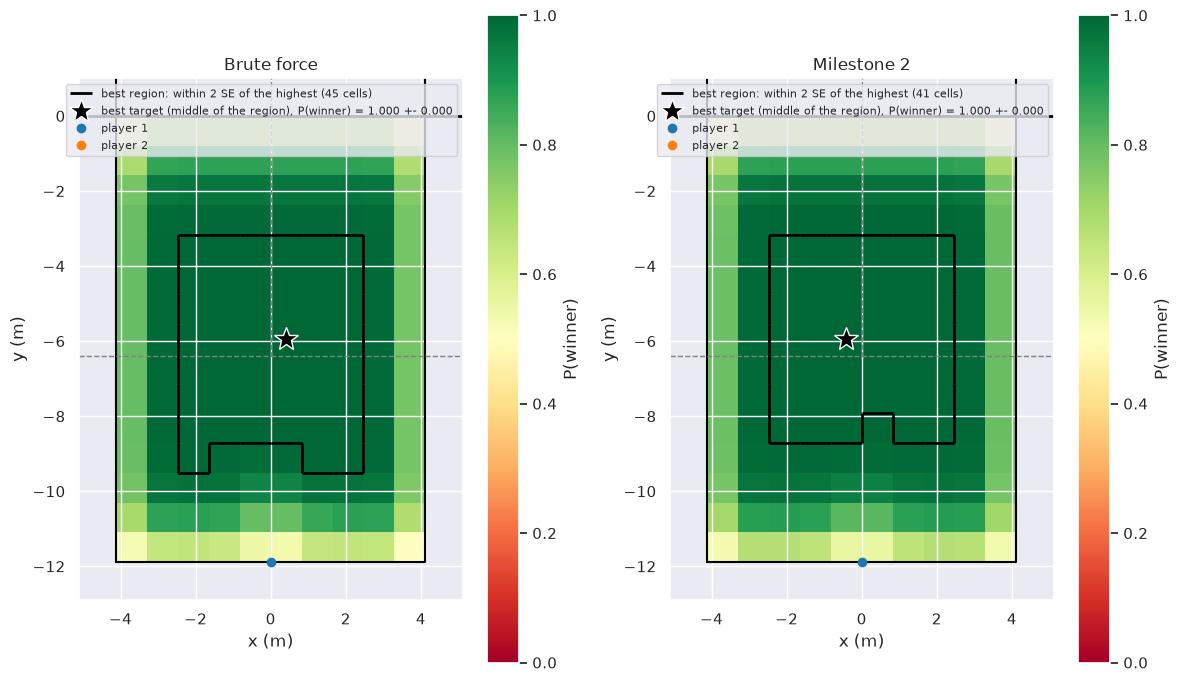

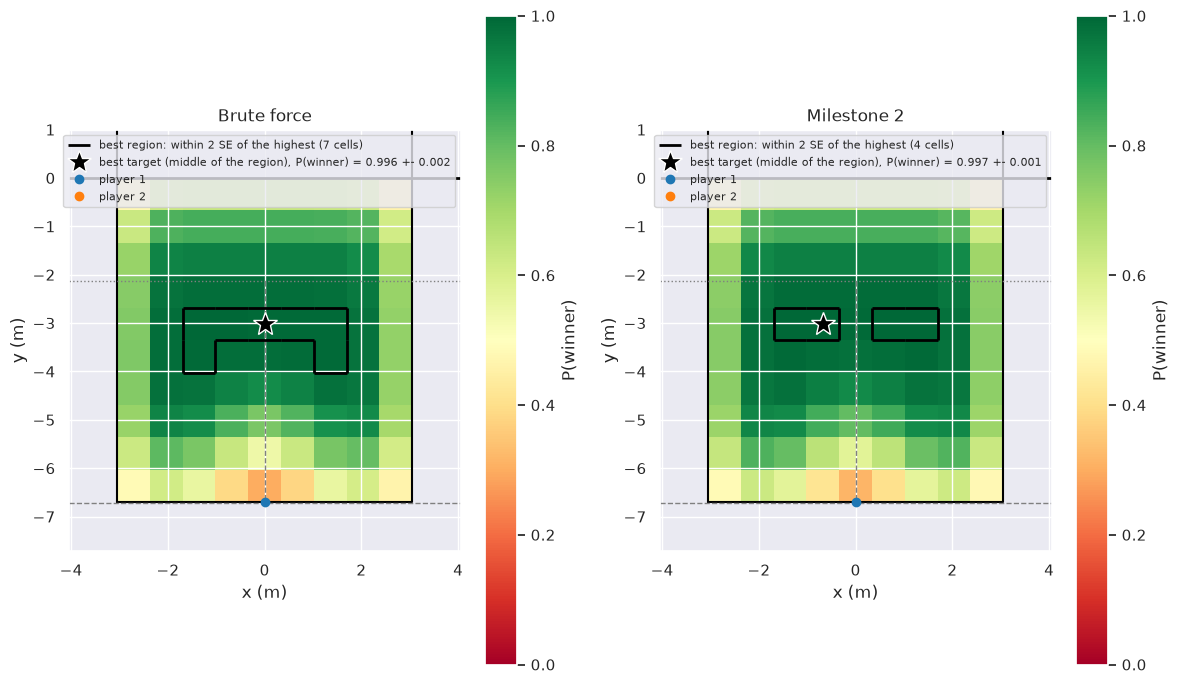

In [16]:
# Plot both maps of the middle serve, for each sport.
for sport in sports:
    name = sport.name
    _ = utils.plot_heatmaps(
        {
            "Brute force": env_maps[name][middle],
            "Milestone 2": m2_maps[name][middle],
        },
        sport.court,
        serves[name][middle],
        figsize=(12.0, 7.0),
    )

**Guided usage**
- Read the `spearman` column
  - Observe a rank correlation above 0.95, the threshold of #713
- Compare the 2 region sizes
  - Observe a larger region for the brute force, which has fewer samples per cell
- Read `env_best_in_m2_region` and `m2_best_in_env_region`
  - Observe `True` for both, except `env_best_in_m2_region` on the 3 short
    pickleball serves: there the highest cell of the brute force ties with the
    best of Milestone 2, and is 0.2 points (2.1 to 2.3 standard errors) below it in
    Milestone 2, just outside its 2 standard error region

**Implementation** `utils.compare_heatmaps(env_heatmap, m2_heatmap)`
- Finds the best region of each map with `find_best_region()` of notebook 01
- Checks the highest cell of each map against the region of the other, and
  computes the Spearman correlation of the 2 maps

In [17]:
hintros.print_obj_info(utils.compare_heatmaps)

- `compare_heatmaps(env_heatmap: pandas.DataFrame, m2_heatmap: pandas.DataFrame) -> Dict[str, Any]`  
  Compare the brute force map of the env with the Milestone 2 map.

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/research/Optimal_strategy_for_racket_sports/notebooks/racket_sports_06_rl_return_utils.py#L456


# Part 4: Train a PPO Agent

## Cell 4.1: Create the Agents on Rescaled Observations

**Goal**
- Create one `PPO` agent per sport and seed, with the default `MlpPolicy`, on its
  own env
- Rescale the observation from the court to $[-1, 1]$ for the agent, while the
  env stays in meters
  - SB3 feeds a `Box` observation to the network as it is, and player 1 at
    $y = -11.885$ m is a constant input that saturated a quarter to a third of
    the first layer (#713, Phase 2)

In [18]:
# Create one agent per sport and seed, on rescaled observations.
models = {}
for sport in sports:
    for seed in config.seeds:
        train_env = gym.wrappers.RescaleObservation(
            utils.build_env(sport), np.float32(-1.0), np.float32(1.0)
        )
        models[(sport.name, seed)] = sb3.PPO(
            "MlpPolicy", train_env, seed=seed, device="cpu", verbose=0
        )
# One wrapper per sport rescales the observations of the evaluation.
rescalers = {
    sport.name: gym.wrappers.RescaleObservation(
        utils.build_env(sport), np.float32(-1.0), np.float32(1.0)
    )
    for sport in sports
}
obs = envs["Tennis"].reset(options={"serve_xy": serves["Tennis"][middle]})[0]
print("obs in meters=", obs)
print("obs rescaled=", rescalers["Tennis"].observation(obs))
print("policy=", models[("Tennis", config.seeds[0])].policy)

obs in meters= [  0.     -11.885   -2.0575   3.2     -2.0575   3.2   ]
obs rescaled= [ 0.         -1.         -0.5         0.26924688 -0.5         0.26924688]
policy= ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=6, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=6, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=150, bias=True)
  (value_net): Linear(in_feature

**Guided usage**
- Read the 2 observations
  - Observe player 1 at $-11.885$ m become $-1$, and the serve fall in $[-1, 1]$
- Read the size of the action head of the policy
  - Observe one output per target cell

## Cell 4.2: Train for a Fixed Budget

**Goal**
- Train each agent on random serves for the budget of the config: 50k steps in
  the reduced run, 75k in the full run, before PPO starts to drift on a reward
  that is almost always 1 (#713, Phase 2)

In [19]:
# Train each agent in place.
for (name, seed), model in models.items():
    model.learn(total_timesteps=config.total_timesteps)
    rewards = [info["r"] for info in model.ep_info_buffer]
    print(
        f"{name}, seed {seed}: {model.num_timesteps} steps, mean reward of the"
        f" last {len(rewards)} points {np.mean(rewards):.3f}"
    )

Tennis, seed 3: 75776 steps, mean reward of the last 100 points 1.000


Tennis, seed 4: 75776 steps, mean reward of the last 100 points 1.000


Tennis, seed 5: 75776 steps, mean reward of the last 100 points 1.000


Pickleball, seed 3: 75776 steps, mean reward of the last 100 points 1.000


Pickleball, seed 4: 75776 steps, mean reward of the last 100 points 1.000


Pickleball, seed 5: 75776 steps, mean reward of the last 100 points 0.980


**Guided usage**
- Read the mean reward of the last points
  - Observe a value close to the best winner probability of Part 3

## Cell 4.3: Score the Agents on the Serves

**Goal**
- For each agent and serve: the greedy cell, whether it is in the best region of
  each map, its regret, and the expected regret over every cell the policy plays

**Description**
- Panels
  - `Results`: one row per sport, seed, and serve; the regrets are in points of
    winner probability against the Milestone 2 map
    - `regret_points`: the highest winner probability minus that of the greedy
      cell
    - `expected_regret_points`: the same for the policy, which plays each cell
      with its probability
    - `random_regret_points`: the same for a uniformly random target

In [20]:
# Map an observation in meters to the action probabilities of `model`, with the
# observation rescaled as in training.
def get_probs(
    model: sb3.PPO, rescaler: gym.ObservationWrapper, obs: np.ndarray
) -> np.ndarray:
    obs_tensor, _ = model.policy.obs_to_tensor(rescaler.observation(obs))
    probs = model.policy.get_distribution(obs_tensor).distribution.probs
    probs_np: np.ndarray = probs.detach().numpy()[0]
    return probs_np


# Score each agent on the serves of its sport.
results = []
for (name, seed), model in models.items():
    get_model_probs = functools.partial(get_probs, model, rescalers[name])
    result = utils.evaluate_policy(
        envs[name], get_model_probs, serves[name], env_maps[name], m2_maps[name]
    )
    results.append(result.assign(sport=name, seed=seed))
results = pd.concat(results, ignore_index=True)
display(results.round(4))

,x1,y1,action,x_m,y_m,in_env_region,in_m2_region,regret_points,random_regret_points,top_prob,expected_p_winner,expected_regret_points,sport,seed
0,-3.4292,1.0667,75,0.4115,-5.9425,True,True,0.00,10.7263,0.1373,0.9977,0.2278,Tennis,3
1,-2.0575,1.0667,75,0.4115,-5.9425,True,True,0.00,10.7112,0.1301,0.9977,0.2309,Tennis,3
2,-0.6858,1.0667,75,0.4115,-5.9425,True,True,0.00,10.7047,0.1204,0.9976,0.2365,Tennis,3
3,-3.4292,3.2000,75,0.4115,-5.9425,True,True,0.00,10.8540,0.1374,0.9977,0.2340,Tennis,3
4,-2.0575,3.2000,75,0.4115,-5.9425,True,True,0.00,10.8395,0.1306,0.9976,0.2368,Tennis,3
5,-0.6858,3.2000,75,0.4115,-5.9425,True,True,0.00,10.8315,0.1209,0.9976,0.2417,Tennis,3
6,-3.4292,5.3333,75,0.4115,-5.9425,True,True,0.00,11.0231,0.1375,0.9976,0.2433,Tennis,3
7,-2.0575,5.3333,75,0.4115,-5.9425,True,True,0.00,11.0019,0.1309,0.9975,0.2457,Tennis,3
8,-0.6858,5.3333,75,0.4115,-5.9425,True,True,0.00,10.9909,0.1213,0.9975,0.2496,Tennis,3
9,-3.4292,1.0667,72,-2.0575,-5.9425,True,True,0.00,10.7263,0.1350,0.9979,0.2101,Tennis,4


**Guided usage**
- Compare `expected_regret_points` with `random_regret_points`
  - Observe less than 1 point for every run, against 11 to 21 points for a random
    target
- Read `top_prob`
  - Observe that the policy is still spread: its greedy cell gets a fraction of
    the probability, so `expected_regret_points` is the fairer summary

**Implementation** `utils.evaluate_policy(env, get_probs, serves, env_heatmaps,
m2_heatmaps)`
- Resets the env with each serve and gets the action probabilities of the policy
- Takes the most likely action as the greedy cell, and scores it with
  `score_target()`
- Weighs the Milestone 2 map with the probabilities for the expected regret

In [21]:
hintros.print_obj_info(utils.evaluate_policy)

- `evaluate_policy(env: research.Optimal_strategy_for_racket_sports.notebooks.racket_sports_06_rl_return_utils.ReturnEnv, get_probs: Callable[[numpy.ndarray], numpy.ndarray], serves: List[Tuple[float, float]], env_heatmaps: List[pandas.DataFrame], m2_heatmaps: List[pandas.DataFrame]) -> pandas.DataFrame`  
  Score a policy on each serve: its greedy cell and its expected regret.

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/research/Optimal_strategy_for_racket_sports/notebooks/racket_sports_06_rl_return_utils.py#L538


## Cell 4.4: Apply the Pass Rule

**Goal**
- Apply the rule of #713, written before the full run: an agent passes if the
  greedy cell of every serve is in the best region of the fresh Milestone 2 map
- Also report, not as a pass condition, the max regrets and a pass with a
  tolerance of 1 point

In [22]:
# Summarize each run, one per sport and seed.
summary = utils.summarize_pass_rule(results)
display(summary.round(4))
print("strict pass for every run=", bool(summary["strict_pass"].all()))
print(
    "runs passing with a 1-point tolerance=",
    f"{int(summary['pass_1_point'].sum())} of {len(summary)}",
)

,sport,seed,n_serves,n_in_m2_region,max_regret_points,max_expected_regret_points,strict_pass,pass_1_point
0,Pickleball,3,9,9,0.10,0.5206,True,True
1,Pickleball,4,9,9,0.10,0.5929,True,True
2,Pickleball,5,9,6,0.38,0.5408,False,True
3,Tennis,3,9,9,0.00,0.2496,True,True
4,Tennis,4,9,9,0.00,0.2233,True,True
5,Tennis,5,9,1,6.60,0.7610,False,False


strict pass for every run= False
runs passing with a 1-point tolerance= 5 of 6


**Guided usage**
- Read `strict_pass` and `pass_1_point`
  - Observe whether a miss of the strict rule is a near miss, within 1 point

**Implementation** `utils.summarize_pass_rule(results)`
- Groups the results by sport and seed, and counts the serves whose greedy cell
  is in the Milestone 2 region
- Passes a run if every serve is in, and with the tolerance if every greedy
  regret is at most 1 point

In [23]:
hintros.print_obj_info(utils.summarize_pass_rule)

- `summarize_pass_rule(results: pandas.DataFrame) -> pandas.DataFrame`  
  Apply the pass rule of #713 to each PPO run, one per sport and seed.

https://github.com/gpsaggese/gpsaggese.github.io/blob/master/research/Optimal_strategy_for_racket_sports/notebooks/racket_sports_06_rl_return_utils.py#L598


# Part 5: Compare Everything

## Cell 5.1: Maps With the Targets of PPO

**Goal**
- See the greedy cells of the agents on both maps of the middle serve

**Description**
- Panels
  - `Brute force` and `Milestone 2`: as in Cell 3.2, with the greedy cell of each
    seed as a purple cross

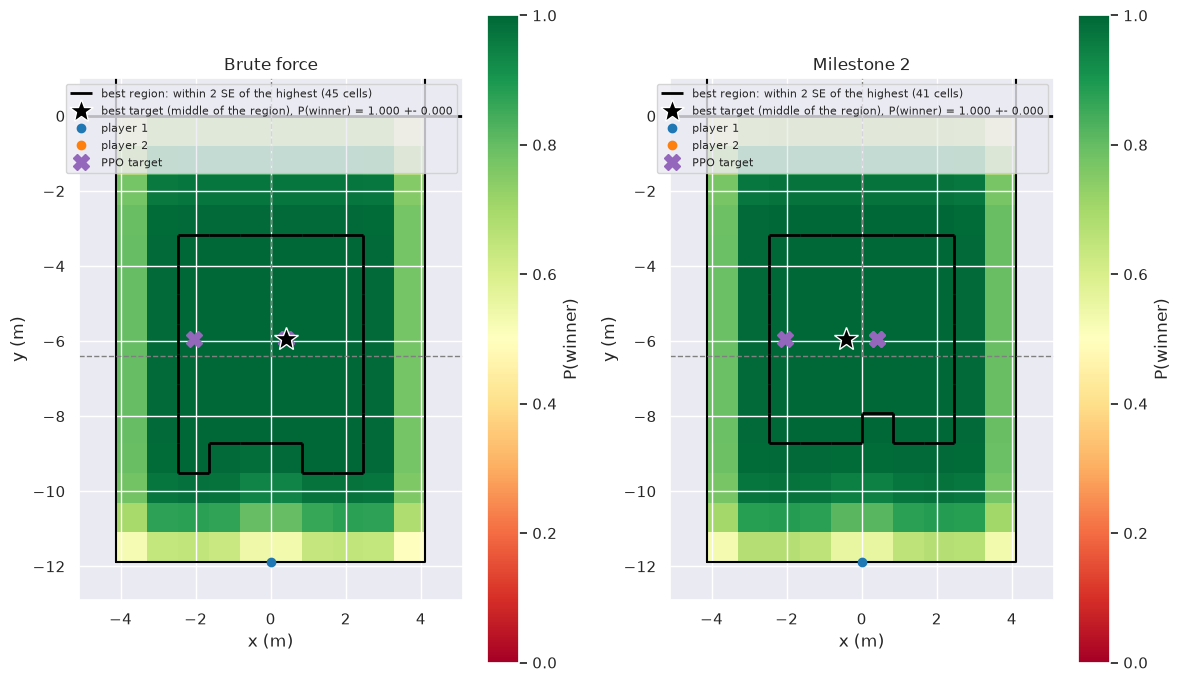

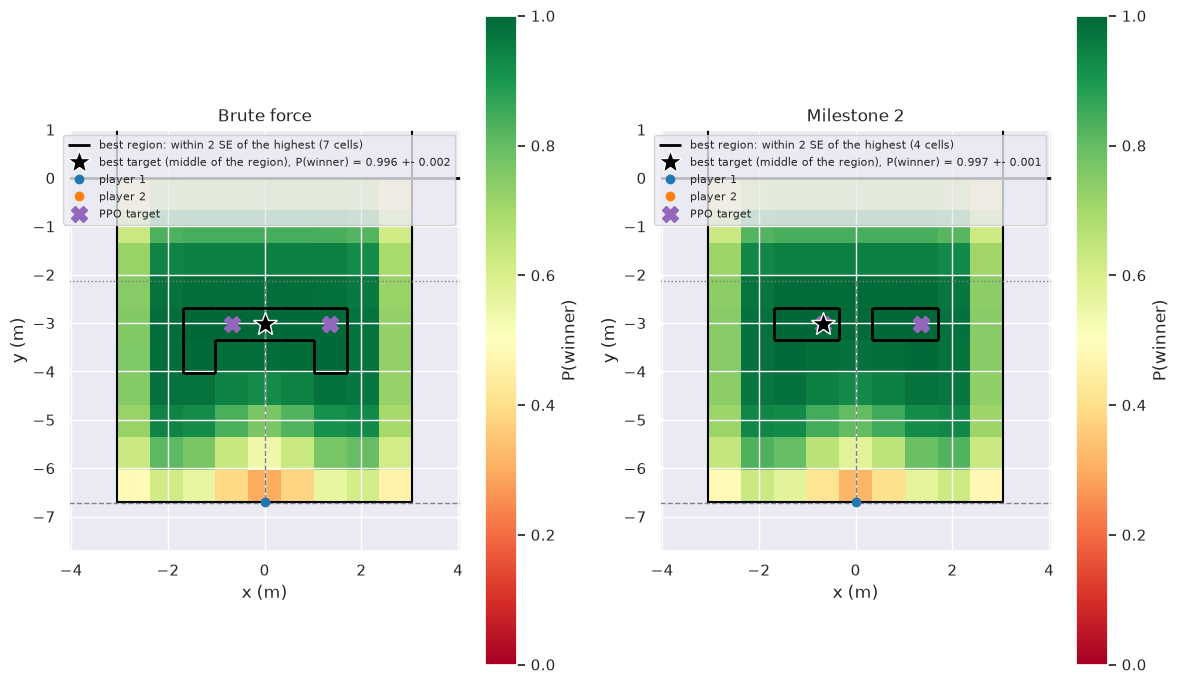

In [24]:
# Plot both maps of the middle serve with the greedy cells, for each sport.
for sport in sports:
    name = sport.name
    middle_serve = serves[name][middle]
    targets_xy = tuple(
        (row.x_m, row.y_m)
        for row in results.itertuples()
        if row.sport == name and (row.x1, row.y1) == middle_serve
    )
    _ = utils.plot_heatmaps(
        {
            "Brute force": env_maps[name][middle],
            "Milestone 2": m2_maps[name][middle],
        },
        sport.court,
        middle_serve,
        targets_xy=targets_xy,
        figsize=(12.0, 7.0),
    )

**Guided usage**
- Find the purple crosses on the pickleball maps
  - Observe them inside the black outline of the best region

## Conclusion

- The env matches Milestone 2 on 9 serves per sport: Spearman 0.98 in tennis and
  0.99 in pickleball, and each map's best cell is in the other's best region on 15
  of 18 serves; the 3 misses are ties within sampling noise (0.2 points)
- PPO's expected regret is under 0.8 points on all 6 runs, against 11 to 21 points
  for a random target
- The strict rule, every greedy cell in the Milestone 2 region, passed 4 of 6 runs;
  seed 5 failed in both sports
- Why: on the flat plateau the policy spreads over tied cells, so its top cell is
  fragile